### 1.1 Imports and Configuration

In [12]:
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torchvision

from torchvision.datasets import OxfordIIITPet
from sklearn.model_selection import train_test_split

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Project directories
# In Colab, this defaults to /content.
# Change this to your repository root if needed.
PROJECT_ROOT = Path.cwd()

DATA_ROOT = PROJECT_ROOT / "data"
RESULTS_DIR = PROJECT_ROOT / "results" / "data_audit"
CONFIG_DIR = PROJECT_ROOT / "configs"

for path in [DATA_ROOT, RESULTS_DIR, CONFIG_DIR]:
    path.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Random seed:", SEED)

Project root: /content
PyTorch: 2.11.0+cpu
Torchvision: 0.26.0+cpu
Random seed: 42


### 1.2 Load Oxford-IIIT Pet Dataset

In [13]:
trainval_dataset = OxfordIIITPet(
    root=str(DATA_ROOT),
    split="trainval",
    target_types=["category", "segmentation"],
    download=True
)

test_dataset = OxfordIIITPet(
    root=str(DATA_ROOT),
    split="test",
    target_types="segmentation",
    download=True
)

print("Trainval samples:", len(trainval_dataset))
print("Test samples:", len(test_dataset))
print("Total samples:", len(trainval_dataset) + len(test_dataset))

Trainval samples: 3680
Test samples: 3669
Total samples: 7349


### 1.3 Inspect One Sample

Image shape: (500, 394, 3)
Mask shape: (500, 394)
Breed category ID: 0
Mask labels:
  Label 1: 52,806 pixels
  Label 2: 114,847 pixels
  Label 3: 29,347 pixels


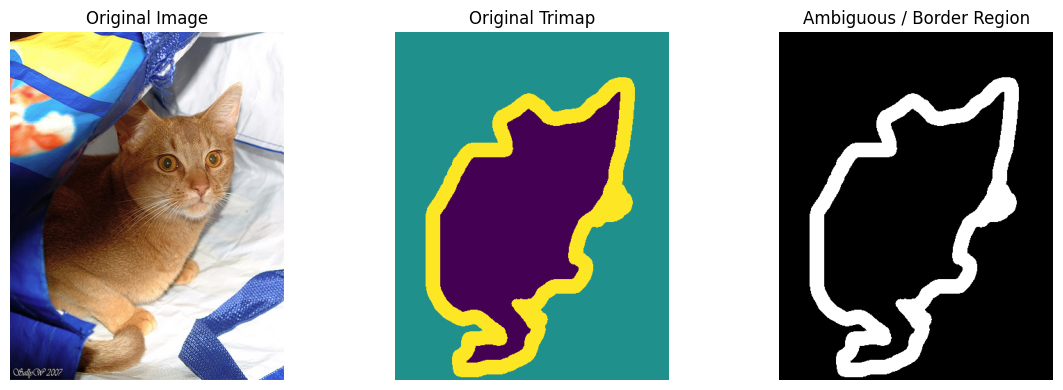

In [14]:
image, (category, mask) = trainval_dataset[0]

image_array = np.array(image)
mask_array = np.array(mask)

print("Image shape:", image_array.shape)
print("Mask shape:", mask_array.shape)
print("Breed category ID:", category)

unique_labels, counts = np.unique(
    mask_array,
    return_counts=True
)

print("Mask labels:")
for label, count in zip(unique_labels, counts):
    print(f"  Label {label}: {count:,} pixels")

assert image_array.shape[:2] == mask_array.shape
assert set(unique_labels).issubset({1, 2, 3})

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(image)
axes[0].set_title("Original Image")

axes[1].imshow(mask_array, cmap="viridis", vmin=1, vmax=3)
axes[1].set_title("Original Trimap")

axes[2].imshow(mask_array == 3, cmap="gray")
axes[2].set_title("Ambiguous / Border Region")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

### 1.4 Full Dataset Audit

In [15]:
pixel_counts = np.zeros(4, dtype=np.int64)
breed_labels = []
image_sizes = []
audit_records = []
invalid_samples = []

for idx in range(len(trainval_dataset)):

    image, (category, mask) = trainval_dataset[idx]

    mask_np = np.array(mask)

    width, height = image.size

    breed_labels.append(int(category))
    image_sizes.append((width, height))

    # Check image and mask dimensions
    if mask_np.shape != (height, width):
        invalid_samples.append({
            "index": idx,
            "issue": "Image-mask size mismatch"
        })
        continue

    # Check labels
    unique_labels = np.unique(mask_np)

    if not np.isin(unique_labels, [1, 2, 3]).all():
        invalid_samples.append({
            "index": idx,
            "issue": f"Unexpected labels: {unique_labels.tolist()}"
        })
        continue

    # Count pixels for each class
    counts = np.bincount(
        mask_np.ravel().astype(np.int64),
        minlength=4
    )

    pixel_counts += counts[:4]

    total_pixels = mask_np.size

    audit_records.append({
        "dataset_index": idx,
        "breed_label": int(category),
        "width": width,
        "height": height,
        "foreground_ratio": counts[1] / total_pixels,
        "background_ratio": counts[2] / total_pixels,
        "border_ratio": counts[3] / total_pixels
    })

    if (idx + 1) % 500 == 0:
        print(f"Processed {idx + 1}/{len(trainval_dataset)} images")

audit_df = pd.DataFrame(audit_records)

print("\nDataset audit completed.")
print("Valid samples:", len(audit_df))
print("Invalid samples:", len(invalid_samples))

Processed 500/3680 images
Processed 1000/3680 images
Processed 1500/3680 images
Processed 2000/3680 images
Processed 2500/3680 images
Processed 3000/3680 images
Processed 3500/3680 images

Dataset audit completed.
Valid samples: 3680
Invalid samples: 0


In [16]:
class_names = {
    1: "Foreground",
    2: "Background",
    3: "Ambiguous Border"
}

total_pixels = pixel_counts[1:4].sum()

print("=== Pixel Class Distribution ===")

for label in [1, 2, 3]:
    count = pixel_counts[label]
    ratio = count / total_pixels

    print(
        f"{class_names[label]}: "
        f"{count:,} pixels ({ratio:.2%})"
    )

print("\n=== Image Resolution Statistics ===")

print(audit_df[["width", "height"]].describe())

print("\n=== Breed Distribution ===")

breed_counts = pd.Series(breed_labels).value_counts()

print("Number of breeds:", breed_counts.size)
print("Min images per breed:", breed_counts.min())
print("Max images per breed:", breed_counts.max())

print("\n=== Data Quality ===")
print("Invalid samples:", invalid_samples[:10])

=== Pixel Class Distribution ===
Foreground: 184,563,866 pixels (29.17%)
Background: 378,924,356 pixels (59.88%)
Ambiguous Border: 69,303,313 pixels (10.95%)

=== Image Resolution Statistics ===
             width       height
count  3680.000000  3680.000000
mean    431.033424   383.420380
std     126.328303   116.833678
min     114.000000   108.000000
25%     333.000000   333.000000
50%     500.000000   375.000000
75%     500.000000   500.000000
max    3264.000000  2606.000000

=== Breed Distribution ===
Number of breeds: 37
Min images per breed: 93
Max images per breed: 100

=== Data Quality ===
Invalid samples: []


### 1.5 Visualize Class Distribution

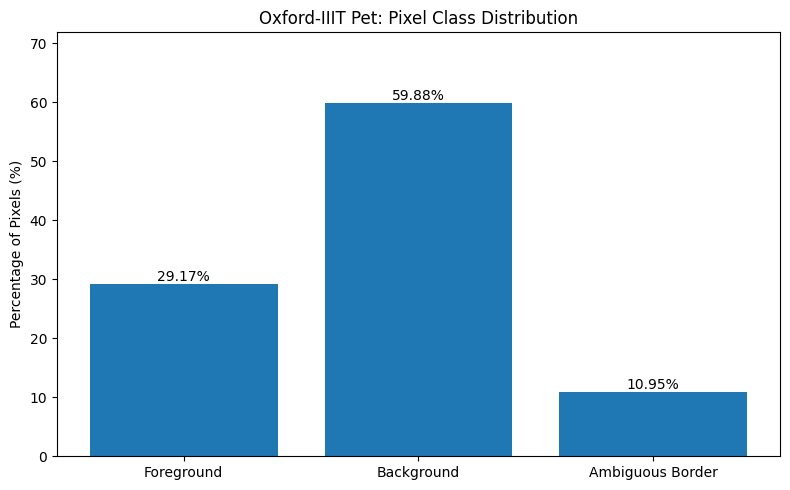

In [17]:
labels = [class_names[i] for i in [1, 2, 3]]

ratios = [
    pixel_counts[i] / total_pixels * 100
    for i in [1, 2, 3]
]

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(labels, ratios)

ax.set_ylabel("Percentage of Pixels (%)")
ax.set_title("Oxford-IIIT Pet: Pixel Class Distribution")
ax.set_ylim(0, max(ratios) * 1.2)

for bar, ratio in zip(bars, ratios):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{ratio:.2f}%",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "class_distribution.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

### 1.6 Visualize Representative Samples

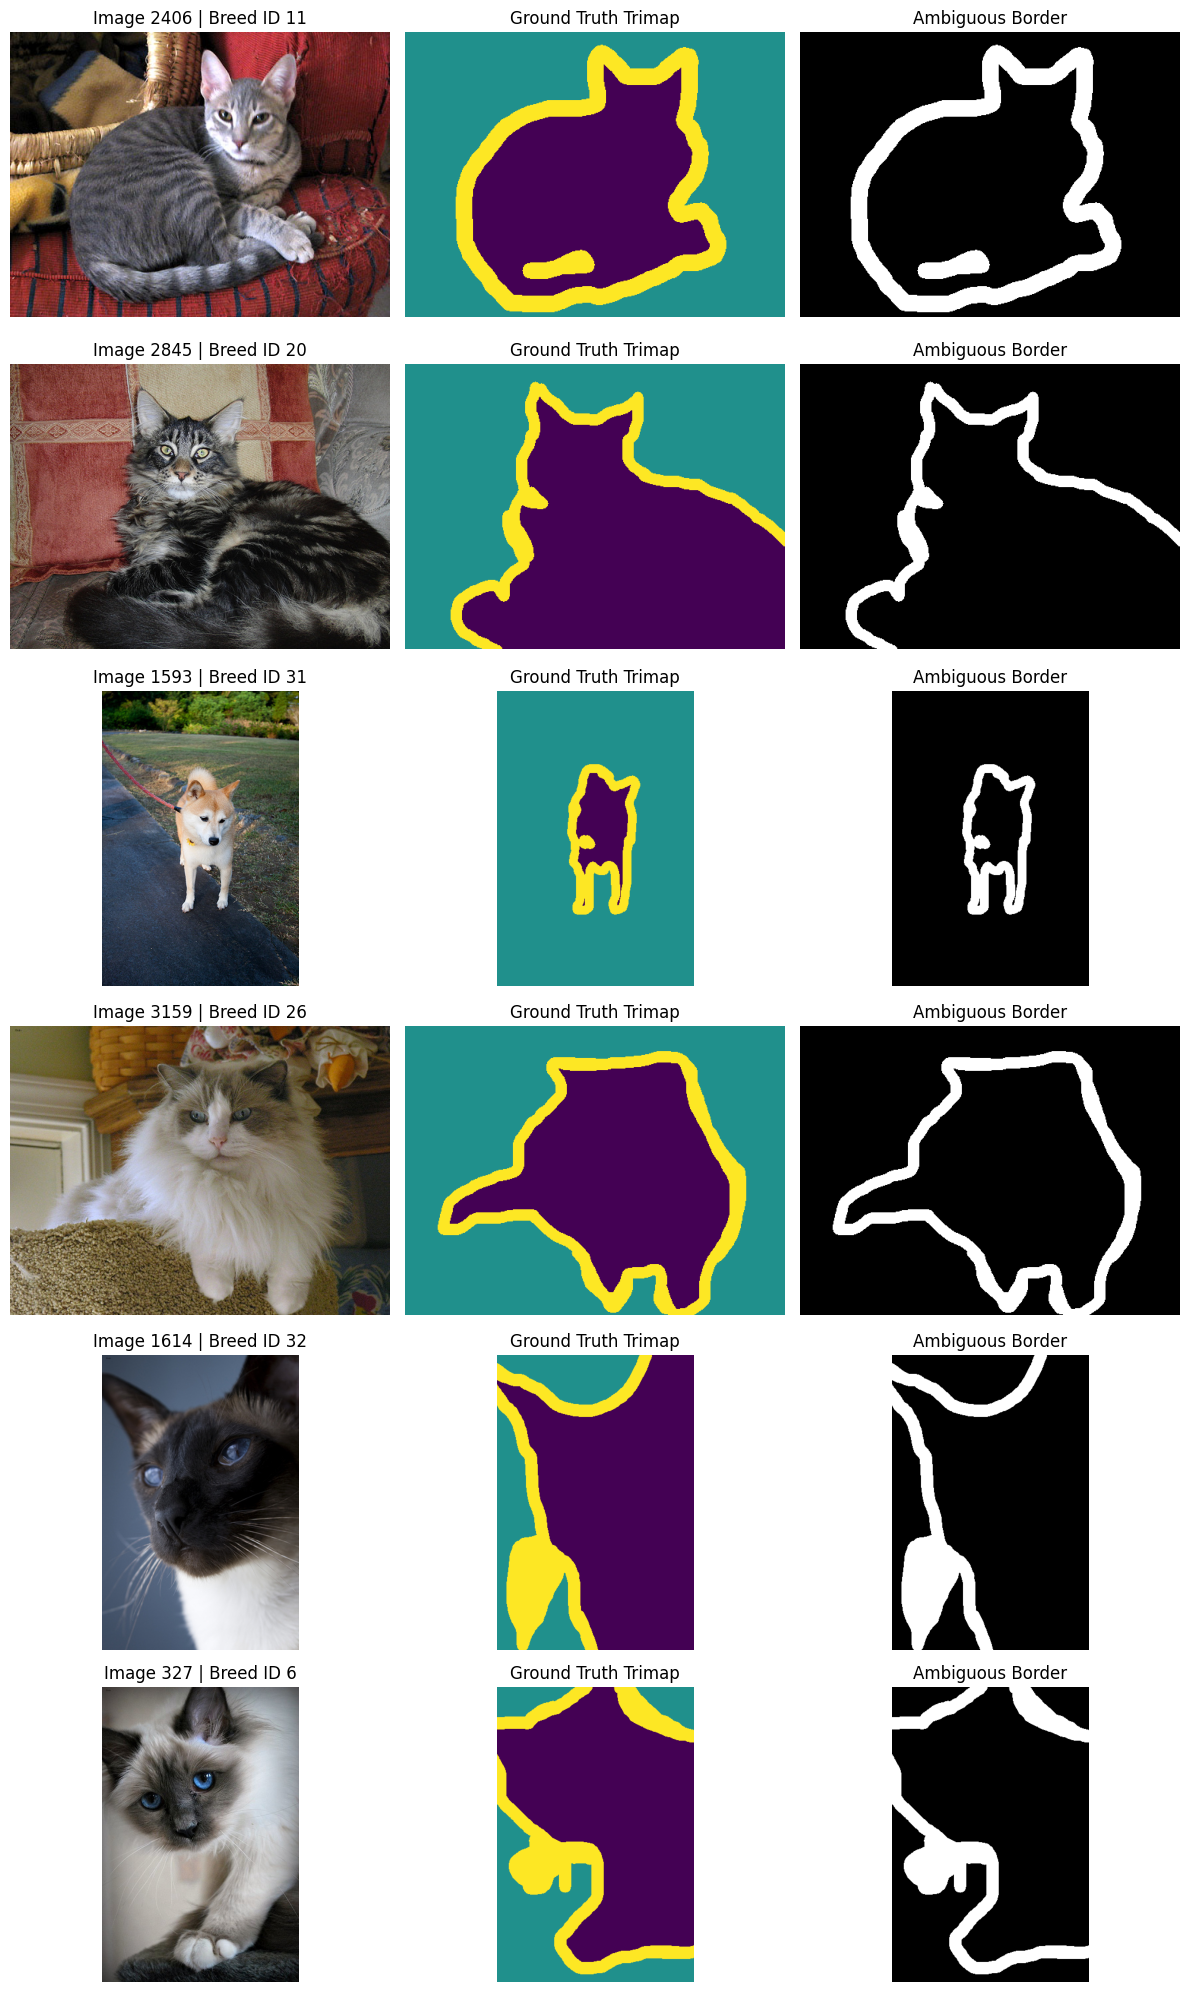

Selected sample indices: [2406, 2845, 1593, 3159, 1614, 327]


In [18]:
rng = np.random.default_rng(SEED)

sample_indices = rng.choice(
    len(trainval_dataset),
    size=6,
    replace=False
)

fig, axes = plt.subplots(
    6, 3,
    figsize=(12, 20)
)

for row, idx in enumerate(sample_indices):

    image, (category, mask) = trainval_dataset[int(idx)]
    mask_np = np.array(mask)

    axes[row, 0].imshow(image)
    axes[row, 0].set_title(
        f"Image {idx} | Breed ID {category}"
    )

    axes[row, 1].imshow(
        mask_np,
        cmap="viridis",
        vmin=1,
        vmax=3
    )
    axes[row, 1].set_title("Ground Truth Trimap")

    axes[row, 2].imshow(
        mask_np == 3,
        cmap="gray"
    )
    axes[row, 2].set_title("Ambiguous Border")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "representative_samples.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Selected sample indices:", sample_indices.tolist())

### 1.7 Fixed Train / Validation Split

In [19]:
all_indices = np.arange(len(trainval_dataset))
breed_labels_np = np.array(breed_labels)

train_indices, val_indices = train_test_split(
    all_indices,
    test_size=0.20,
    random_state=SEED,
    stratify=breed_labels_np
)

train_indices = np.sort(train_indices)
val_indices = np.sort(val_indices)

print("Train samples:", len(train_indices))
print("Validation samples:", len(val_indices))
print("Official test samples:", len(test_dataset))

# Verify no index overlap
assert len(set(train_indices) & set(val_indices)) == 0

assert (
    len(train_indices) + len(val_indices)
    == len(trainval_dataset)
)

print("Train/Validation split verified.")

Train samples: 2944
Validation samples: 736
Official test samples: 3669
Train/Validation split verified.


In [20]:
split_df = pd.DataFrame({
    "dataset_index": all_indices,
    "breed_label": breed_labels_np,
    "split": "train"
})

split_df.loc[
    split_df["dataset_index"].isin(val_indices),
    "split"
] = "val"

split_df = split_df.sort_values(
    "dataset_index"
).reset_index(drop=True)

split_path = CONFIG_DIR / "train_val_split.csv"

split_df.to_csv(split_path, index=False)

split_metadata = {
    "dataset": "Oxford-IIIT Pet",
    "source_split": "trainval",
    "strategy": "stratified_by_breed",
    "seed": SEED,
    "train_count": len(train_indices),
    "val_count": len(val_indices),
    "official_test_count": len(test_dataset),
    "train_fraction": 0.8,
    "val_fraction": 0.2
}

with open(
    CONFIG_DIR / "split_metadata.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(split_metadata, f, indent=2)

print("Saved:", split_path)
print(split_df["split"].value_counts())

Saved: /content/configs/train_val_split.csv
split
train    2944
val       736
Name: count, dtype: int64


### 1.8 Save Dataset Audit Results

In [21]:
# Save per-image statistics
audit_df.to_csv(
    RESULTS_DIR / "per_image_statistics.csv",
    index=False
)

# Save dataset-level summary
audit_summary = {
    "dataset_name": "Oxford-IIIT Pet",
    "source_url": "https://www.robots.ox.ac.uk/~vgg/data/pets/",
    "license": "CC BY-SA 4.0",
    "trainval_samples": len(trainval_dataset),
    "test_samples": len(test_dataset),
    "total_samples": (
        len(trainval_dataset) + len(test_dataset)
    ),
    "num_breeds": len(set(breed_labels)),
    "mask_labels": class_names,
    "pixel_counts_trainval": {
        class_names[i]: int(pixel_counts[i])
        for i in [1, 2, 3]
    },
    "pixel_ratios_trainval": {
        class_names[i]: float(pixel_counts[i] / total_pixels)
        for i in [1, 2, 3]
    },
    "invalid_sample_count": len(invalid_samples),
    "representative_indices": sample_indices.tolist(),
    "seed": SEED,
    "torch_version": torch.__version__,
    "torchvision_version": torchvision.__version__
}

summary_path = RESULTS_DIR / "data_audit_summary.json"

with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(
        audit_summary,
        f,
        indent=2,
        ensure_ascii=False
    )

print("Data audit files saved successfully.")

print("\nSaved outputs:")
print("- data_audit_summary.json")
print("- per_image_statistics.csv")
print("- class_distribution.png")
print("- representative_samples.png")
print("- train_val_split.csv")
print("- split_metadata.json")

Data audit files saved successfully.

Saved outputs:
- data_audit_summary.json
- per_image_statistics.csv
- class_distribution.png
- representative_samples.png
- train_val_split.csv
- split_metadata.json


### 1.9 Inspect Potential Annotation Issues

Potentially suspicious samples: [1404, 2407, 2410, 2437, 2833, 2889, 3246]


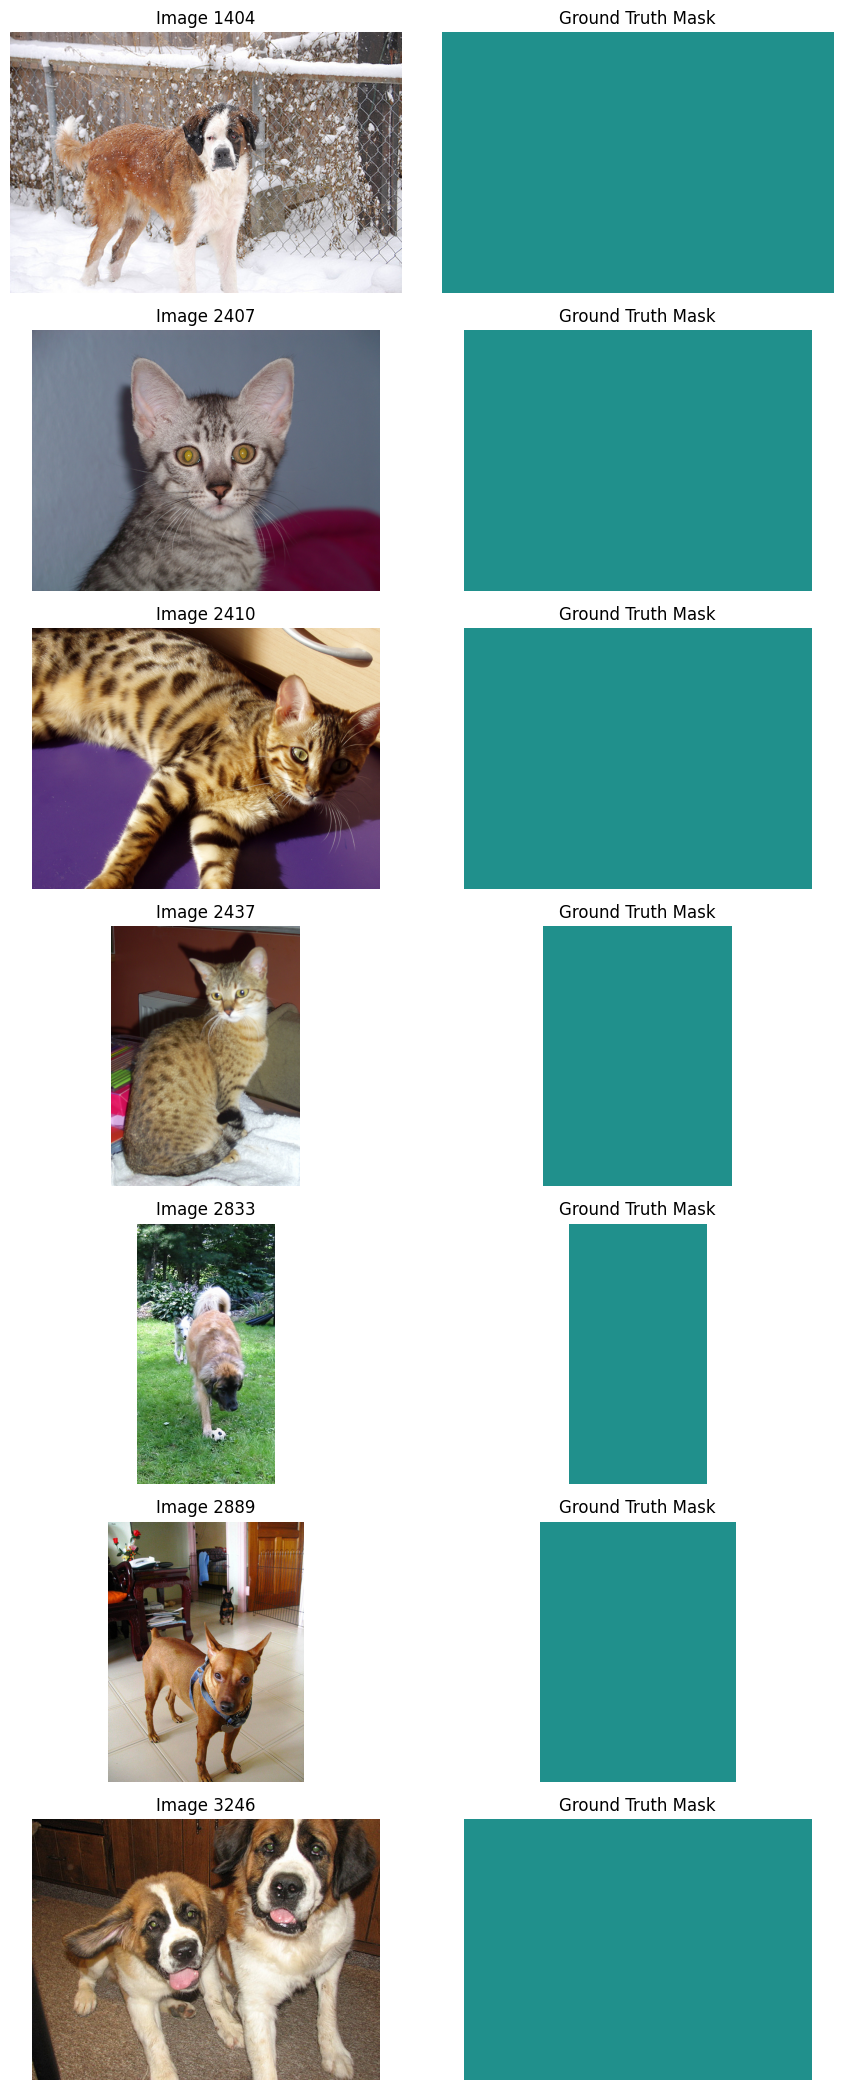

In [22]:
suspicious_indices = audit_df.loc[
    (audit_df["foreground_ratio"] == 0) &
    (audit_df["border_ratio"] == 0),
    "dataset_index"
].tolist()

print("Potentially suspicious samples:", suspicious_indices)

fig, axes = plt.subplots(
    len(suspicious_indices), 2,
    figsize=(9, 3 * len(suspicious_indices))
)

for row, idx in enumerate(suspicious_indices):
    image, (_, mask) = trainval_dataset[idx]

    axes[row, 0].imshow(image)
    axes[row, 0].set_title(f"Image {idx}")

    axes[row, 1].imshow(
        np.array(mask),
        cmap="viridis",
        vmin=1,
        vmax=3
    )
    axes[row, 1].set_title("Ground Truth Mask")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()


## 1.10 Data Quality Filtering

During the dataset audit, we identified seven images with invalid
segmentation annotations. Although pets are clearly visible, all
pixels in their masks are labeled as background.

These samples are excluded from training to avoid introducing
incorrect supervision. The original images and annotations are
preserved, and the excluded indices are documented.

The original validation and official test splits remain unchanged.

In [23]:
INVALID_MASK_INDICES = [
    1404, 2407, 2410, 2437, 2833, 2889, 3246
]

# Preserve the original split manifest
clean_split_df = split_df.copy()

# Verify that all excluded samples belong to the training set
invalid_rows = clean_split_df[
    clean_split_df["dataset_index"].isin(INVALID_MASK_INDICES)
]

assert len(invalid_rows) == len(INVALID_MASK_INDICES)
assert (invalid_rows["split"] == "train").all()

# Record data quality status
clean_split_df["data_quality"] = "valid"

clean_split_df.loc[
    clean_split_df["dataset_index"].isin(INVALID_MASK_INDICES),
    "data_quality"
] = "missing_segmentation_mask"

# Exclude invalid samples
clean_split_df.loc[
    clean_split_df["data_quality"] != "valid",
    "split"
] = "excluded"

# Save cleaned split manifest
clean_split_path = CONFIG_DIR / "train_val_split_clean.csv"

clean_split_df.to_csv(
    clean_split_path,
    index=False
)

# Save an explicit issue log
issues_df = clean_split_df[
    clean_split_df["split"] == "excluded"
].copy()

issues_df.to_csv(
    RESULTS_DIR / "data_quality_issues.csv",
    index=False
)

print("=== Final Dataset Split ===")
print(clean_split_df["split"].value_counts())

print("\nExcluded samples:", len(issues_df))
print("Saved:", clean_split_path)


=== Final Dataset Split ===
split
train       2937
val          736
excluded       7
Name: count, dtype: int64

Excluded samples: 7
Saved: /content/configs/train_val_split_clean.csv
